# Module 3: Statistics Assessment

In [1]:
import numpy as np
import pandas as pd

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
%matplotlib inline

In [4]:
import warnings
warnings.filterwarnings("ignore")

In [5]:
df=pd.read_csv("customer_behavior.csv")

In [6]:
df.head()

,CustomerID,Gender,Region,PurchaseAmount,ProductCategory,Churn,CampaignGroup
0,1001,Male,South,256.07,Fashion,No,A
1,1002,Female,South,NaN,Electronics,Yes,B
2,1003,Female,West,1194.41,Fashion,No,A
3,1004,Female,South,413.06,Grocery,No,A
4,1005,Male,West,1556.32,Fashion,Yes,A


In [7]:
df.shape

(5000, 7)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       5000 non-null   int64  
 1   Gender           4903 non-null   str    
 2   Region           4825 non-null   str    
 3   PurchaseAmount   4850 non-null   float64
 4   ProductCategory  4474 non-null   str    
 5   Churn            4735 non-null   str    
 6   CampaignGroup    4815 non-null   str    
dtypes: float64(1), int64(1), str(5)
memory usage: 373.7 KB


In [9]:
df.isnull().sum()

CustomerID           0
Gender              97
Region             175
PurchaseAmount     150
ProductCategory    526
Churn              265
CampaignGroup      185
dtype: int64

In [10]:
df.describe()

,CustomerID,PurchaseAmount
count,5000.000000,4850.000000
mean,3500.500000,1003.950670
std,1443.520003,482.113122
min,1001.000000,0.000000
25%,2250.750000,673.642500
50%,3500.500000,998.080000
75%,4750.250000,1327.077500
max,6000.000000,2688.880000


Insights: Here the dataset contains 5000 data with 7 variables with 6 variables containing null values. Now looking at the summary statistics, we can see that both the variables, customer Id and PurchaseAmount has outliers. but here the customer Id since it is a label for identification we only need to consider the outliers of the variable, PurchaseAmount.

## Question 1

#### What is the average, median, and mode of PurchaseAmount?

In [11]:
df1=df["PurchaseAmount"].dropna()

In [12]:
print("Mean:",df1.mean())

Mean: 1003.9506701030928


In [13]:
print("Median:",df1.median())

Median: 998.0799999999999


In [14]:
print("Mode:",df1.mode())

Mode: 0    0.0
Name: PurchaseAmount, dtype: float64


Conclusion: Here the Mean, Medianand Mode of the variable is 1003.95, 998.08 and 0 respectively.

## Question 2

#### Are there any outliers in the PurchaseAmount data?

<Axes: ylabel='PurchaseAmount'>

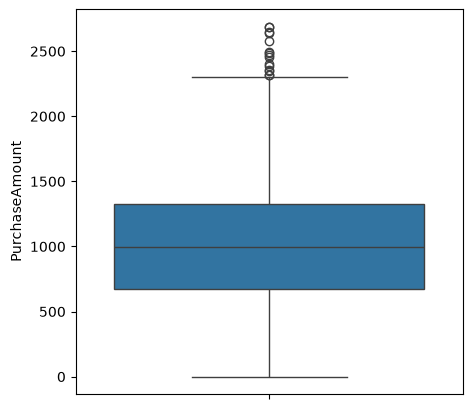

In [15]:
plt.figure(figsize=(5,5))
sns.boxplot(df1)

In [16]:
q1= df1.quantile(0.25)
q3 = df1.quantile(0.75)
print("First quartile is:",round(q1,2))
print("Third quartile is:",round(q3,2))

First quartile is: 673.64
Third quartile is: 1327.08


In [17]:
q1,q3=np.percentile(df1,[25,75])
print("First quartile is:",round(q1,2))
print("Third quartile is:",round(q3,2))

First quartile is: 673.64
Third quartile is: 1327.08


In [18]:
iqr = q3-q1
print(iqr.round(2))

653.44


In [19]:
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr
print(lower_limit, upper_limit)

-306.51000000000033 2307.2300000000005


In [20]:
outlier = []

In [21]:
for x in df1:
  if x<lower_limit or x>upper_limit:
    outlier.append(x)
print(outlier)

[2318.33, 2496.41, 2688.69, 2349.16, 2578.89, 2384.19, 2457.05, 2316.19, 2400.69, 2357.41, 2688.88, 2643.88, 2472.62, 2484.75, 2642.06]


In [22]:
len(outlier)

15

In [23]:
def detect_outliers(data):
    Outlier = []
    threshold = 3
    mean = np.mean(data)
    print("Mean:", mean)
    std = np.std(data)
    print("Std Dev:", std)

    for i in data:
        z_score = (i - mean) / std
        if np.abs(z_score) > threshold:
            Outlier.append(i)
            
    return Outlier

In [24]:
detect_outliers(df1)

Mean: 1003.9506701030928
Std Dev: 482.06341698716864


[2496.41,
 2688.69,
 2578.89,
 2457.05,
 2688.88,
 2643.88,
 2472.62,
 2484.75,
 2642.06]

In [25]:
Outlier=detect_outliers(df1)
len(Outlier)

Mean: 1003.9506701030928
Std Dev: 482.06341698716864


9

Conclusion: We use Boxplot to visualize the outliers. Also, we can use the IQR method as well as z Score method to identify the outliers. In this case, if we use the IQR method, we will get 15 outliers but if we use the z score method we will get only 9 outliers.

## Question 3

#### Is there any skewness or kurtosis in the PurchaseAmount distribution?

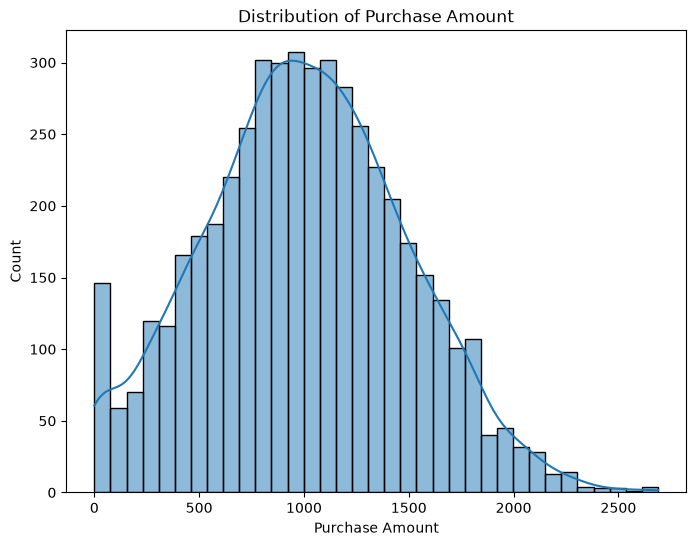

In [26]:
plt.figure(figsize=(8,6))
sns.histplot(df1,kde=True)
plt.xlabel("Purchase Amount")
plt.ylabel("Count")
plt.title("Distribution of Purchase Amount")
plt.show()

In [27]:
from scipy.stats import skew

In [28]:
skew(df1).round(2)

np.float64(0.11)

In [29]:
kurtosis=df1.kurtosis()
kurtosis.round(2)

np.float64(-0.26)

OR

In [30]:
from scipy.stats import kurtosis

In [31]:
kurtosis(df1).round(2)

np.float64(-0.26)

Conclusion:Histoplot of the distribtion of the variable, shows that the variable is positively skewed with the skewness value is 0.11, but the value of skewness is between 0 and 0.5 which is little skewed. So we can conclude that the variable is approximately symmetric. The value of kurtosis is -0.26, since the value is less than 0, we can say that the variable is platykurtic which means the variable is lighter tails with fewer extreme values.

## Question 4

#### Is there a significant difference in spending between male and female customers?

In [32]:
df4=df["Gender"].dropna()
df4.isnull().sum()

np.int64(0)

In [33]:
Male=df[df["Gender"]=="Male"]["PurchaseAmount"]
Female=df[df["Gender"]=="Female"]["PurchaseAmount"]

In [34]:
print("Average spending by male customers is:", round(Male.mean(),2))
print("Average spending by female customers is:", round(Female.mean(),2))

Average spending by male customers is: 1019.18
Average spending by female customers is: 987.87


In [35]:
from scipy import stats

In [36]:
t_stat, p_value=stats.ttest_ind(Male,Female)

print("T-Statistic:", t_stat)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject the Null Hypothesis")
else:
    print("Fail to Reject the Null Hypothesis")

T-Statistic: nan
P-Value: nan
Fail to Reject the Null Hypothesis


Conclusion: There is significant difference in the average spending of male and female customers.

## Question 5

#### Is there a relationship between Product Category and customer churn?

In [37]:
df5=df.dropna(subset=["ProductCategory","Churn"])
df5=pd.crosstab(df5["ProductCategory"], df5["Churn"])
df5

Churn,No,Yes
ProductCategory,,
Electronics,785,541
Fashion,839,607
Grocery,855,604


In [38]:
chi2, p_value, dof, expected = stats.chi2_contingency(df5)

print("Chi-Square Statistic:", chi2)
print("P-Value:", p_value)
print("Degrees of Freedom:", dof)
print("Expected Frequencies:\n", expected)

if p_value < 0.05:
    print("There is a significant difference between Product Category and customer churn.")
else:
    print("There is no significant relationship between Product Category and customer churn.")

Chi-Square Statistic: 0.3960436652673918
P-Value: 0.8203519424988512
Degrees of Freedom: 2
Expected Frequencies:
 [[776.9212952  549.0787048 ]
 [847.23091468 598.76908532]
 [854.84779012 604.15220988]]
There is no significant relationship between Product Category and customer churn.


Conclusion: There is no significant evidence of a relationship between the Product Category and customer churn. That is the product category doesnot influence the customer churn.

## Question 6

#### Does PurchaseAmount vary significantly across different regions?

In [39]:
df6=df.dropna(subset=["Region","PurchaseAmount"])

In [40]:
North=df6[df6["Region"]=="North"]["PurchaseAmount"]
South=df6[df6["Region"]=="South"]["PurchaseAmount"]
East=df6[df6["Region"]=="East"]["PurchaseAmount"]
West=df6[df6["Region"]=="West"]["PurchaseAmount"]

In [41]:
df6=df6.groupby("Region")["PurchaseAmount"].mean()
df6

Region
East     1009.946017
North    1013.017952
South     997.603877
West      995.247327
Name: PurchaseAmount, dtype: float64

Here there is difference between the average purchase amount of different region, Now we have to check if this difference is significant or not.

In [42]:
f_stat, p_value = stats.f_oneway(North, South, East, West)

print("F-Statistic:", f_stat)
print("P-Value:", p_value)

if p_value < 0.05:
    print("At least one group mean is significantly different")
else:
    print("No significant difference between group means")

F-Statistic: 0.38966786354806715
P-Value: 0.7604528027310102
No significant difference between group means


Conclusion: The difference in the average purchase amount of different region is not signifcant. Which means that the Average purchase amount of different regions are the same.

## Question 7

#### Which email campaign (A or B) performed better in terms of average Purchase Amount?

In [43]:
df7=df[["PurchaseAmount","CampaignGroup"]].dropna()

In [44]:
average_purchase=df7.groupby("CampaignGroup")["PurchaseAmount"].mean()
average_purchase

CampaignGroup
A    1011.945587
B     994.339965
Name: PurchaseAmount, dtype: float64

In [45]:
if average_purchase["A"]>average_purchase["B"]:
    print("Campaign A performed better than Campaingn B.")
elif average_purchase["A"]<average_purchase["B"]: 
    print("Campaign B performed better than Campaingn A.")
else:
    print("Campaign A and Campaingn B performed equally.")

Campaign A performed better than Campaingn B.


In [46]:
Campaign_a=df7[df7["CampaignGroup"]=="A"]["PurchaseAmount"]
Campaign_b=df7[df7["CampaignGroup"]=="B"]["PurchaseAmount"]

In [47]:
t_stat, p_value=stats.ttest_ind(Campaign_a,Campaign_b)

print("T-Statistic:", t_stat)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject the Null Hypothesis")
else:
    print("Fail to Reject the Null Hypothesis")

T-Statistic: 1.2432134501809364
P-Value: 0.21385165083767033
Fail to Reject the Null Hypothesis


Conclusion: There is no significant difference between Campaign A and Campaign B.

## Question 8

#### Can we assume Purchase Amount follows a normal distribution?

In [48]:
df8=df["PurchaseAmount"].dropna()

In [49]:
print("mean=",round(df8.mean(),2))
print("median=",round(df8.median(),2))
print("Skewness=",round(df8.skew(),2))
print("Kurtosis=",round(df8.kurtosis(),2))

mean= 1003.95
median= 998.08
Skewness= 0.11
Kurtosis= -0.26


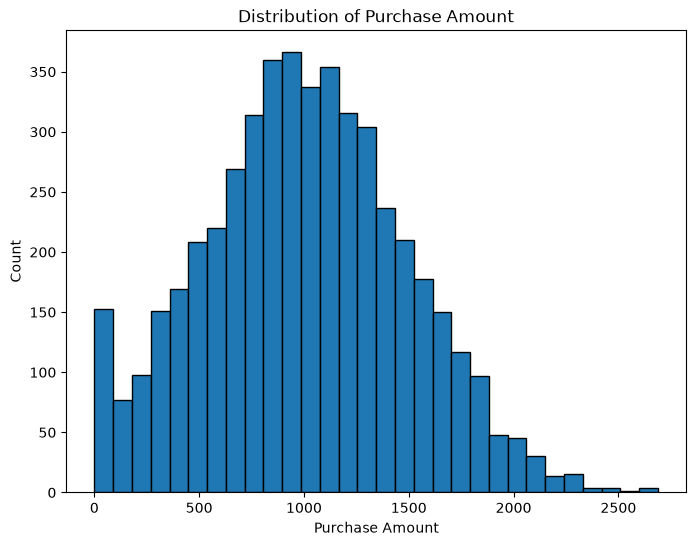

In [50]:
plt.figure(figsize=(8,6))
plt.hist(df8,bins=30,edgecolor="Black")
plt.xlabel("Purchase Amount")
plt.ylabel("Count")
plt.title("Distribution of Purchase Amount")
plt.show()

In [51]:
statistics, p_value=stats.shapiro(df8)

print("W-Statistic:", statistics)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject the Null Hypothesis")
else:
    print("Fail to Reject the Null Hypothesis")

W-Statistic: 0.994950574430403
P-Value: 5.744135543819118e-12
Reject the Null Hypothesis


Conclusion: The variable 'PurchaseAmount' is not normally distributed.

## Question 9

#### What insights can we gain by applying the Central Limit Theorem?

Central limit theorem stated that the sampling distribution of the sample mean becomes approximately normal as the sample size increases even if the population itself is not normal.
To Demonstrate this, we are using boostraping method and takes 2000 samples of size length of df1 with replacement and study the distribution of their sample means.

In [52]:
n=len(df1)
bootstrap_sample_means=[]

for i in range(2000):
    sample=df1.sample(n=n, replace=True)
    bootstrap_sample_means.append(sample.mean())

bootstrap_sample_means=np.array(bootstrap_sample_means)

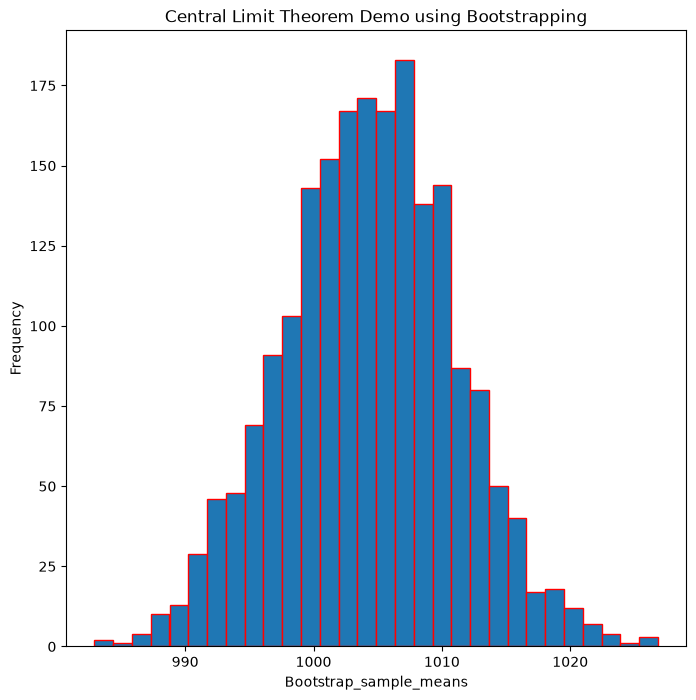

In [53]:
plt.figure(figsize=(8,8))
plt.hist(bootstrap_sample_means, bins=30, edgecolor="Red")
plt.title("Central Limit Theorem Demo using Bootstrapping")
plt.xlabel("Bootstrap_sample_means")
plt.ylabel("Frequency")
plt.show()

OR

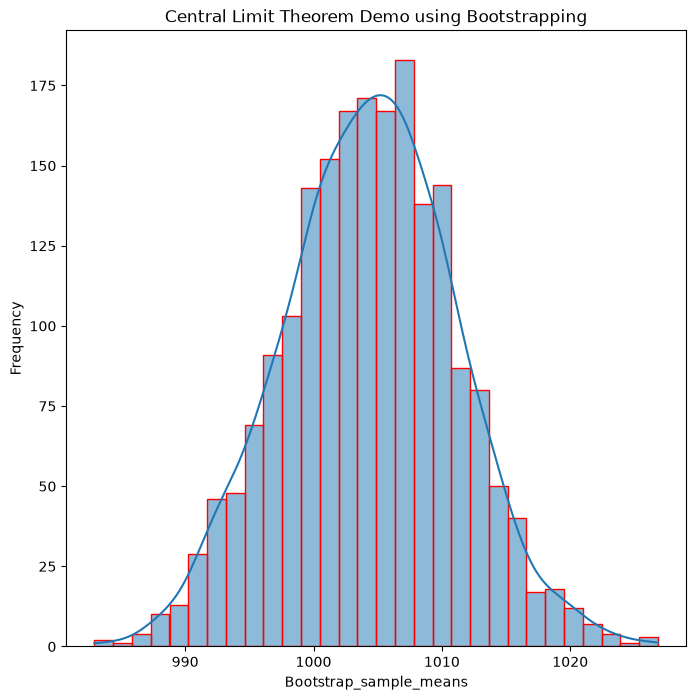

In [54]:
plt.figure(figsize=(8,8))
sns.histplot(bootstrap_sample_means, bins=30, edgecolor="Red",kde=True)
plt.title("Central Limit Theorem Demo using Bootstrapping")
plt.xlabel("Bootstrap_sample_means")
plt.ylabel("Frequency")
plt.show()

In [55]:
print("Original Mean:",round(df1.mean(),2))
print("Bootstrap Mean:",round(bootstrap_sample_means.mean(),2))
print("Bootstrap Std Error:",round(bootstrap_sample_means.std(ddof=1),2))

Original Mean: 1003.95
Bootstrap Mean: 1004.35
Bootstrap Std Error: 6.66


From the histogram it is evident that the distribution of the bootstrap sample means approximately follows normal distribution. The Original mean and the mean of the bootstrap sample means are almost equal.
Now to check if it is statistically evident, we use shapiro test for normality.

H0: Purchase Amount follows a normal distribution. 
H1: Purchase Amount doesnot follows a normal distribution.

In [56]:
statistics, p_value=stats.shapiro(bootstrap_sample_means)

print("W-Statistic:", statistics)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject the Null Hypothesis")
else:
    print("Fail to Reject the Null Hypothesis")

W-Statistic: 0.9991864488626089
P-Value: 0.5362462366808903
Fail to Reject the Null Hypothesis


Conclusion: Therefore bootstrap_sample_means follows a normal distribution. 
That is the sampling distribution of the sample means of the variable 'PurchaseAmount' follows a normal distribtuion.

## Question 10

#### What is the 95% confidence interval for the average PurchaseAmount?

In [57]:
n=len(df1)
mean=df1.mean()
std=df1.std(ddof=1)

In [58]:
std_error=std/np.sqrt(n)

In [59]:
t_value=stats.t.ppf(0.975,df=n-1)

In [60]:
lower_limit=mean-t_value*std_error
upper_limit=mean+t_value*std_error

In [61]:
print("Sample Size:", n)
print("Mean Purchase Amount:", round(mean,2))
print("95% Confidence Interval:", round(lower_limit,2), ",", round(upper_limit,2))

Sample Size: 4850
Mean Purchase Amount: 1003.95
95% Confidence Interval: 990.38 , 1017.52


Conclusion: The Confidence Interval is (990.38, 1017.52)